# Lazy Note — Phase 1 Pipeline: Asynchronous Rolling 10-Minute Macro-Batch (Real Lecture)

> **Purpose of this notebook.** It is both an *executable sandbox* and the *implementation context document* for the real backend. Every design decision, invariant, data structure and failure mode is documented in the markdown cells so that coding agents can implement the production services (FastAPI + PostgreSQL + R2 + background worker) without re-deriving anything.
>
> It is derived from `samplepipeline.ipynb` (single-pass, synchronous finalize). What changed:
>
> | Aspect | `samplepipeline.ipynb` (base) | `pipelinephase1.ipynb` (this notebook) |
> | --- | --- | --- |
> | Audio | 60 s clip of `conv1.m4a` | Full real lecture `sample/Gnn part 1.m4a` (~60 MB, long-form) |
> | Transport chunks | 40 KB raw byte slices (~10 s) | **30 s, cluster-aligned** WebM/Opus chunks (what `MediaRecorder.start(30000)` emits) |
> | Processing trigger | Once, after *Stop* | **Rolling**: every 20 contiguous verified chunks (10 min) *while still recording*, plus a final tail window on *Stop* |
> | STT slicing | ~10 min slices cut at the first speech boundary after 10 min | 10-min windows cut at the **last natural breath pause ≥ 400 ms** (silence-bounded) with a **carryover tail** |
> | Timestamps | One offset map for the whole file | **One offset map per window**, anchored to the wall-clock cluster timecode of the window |
> | Flushing | None | Intermediates flushed after each window; transport chunks flushed only after `master_raw.webm` is verified |
> | Output folder | `result/pipeline_test/` | `result/pipeline_phase1/` (organised, numbered sub-folders) |

## 0. Why a rolling pipeline?

In a synchronous pipeline the server waits for **Stop**, then stitches, runs DSP, compacts silence and calls the STT API for the whole lecture. For a 90-minute lecture that is a long wait. In the rolling pipeline a background job fires as soon as **20 contiguous verified 30-second chunks (10 minutes)** exist on the server. By the time the student taps **Stop**, almost everything is already transcribed and only the **tail** (< 10 min + carryover) remains.

| Lecture length | Synchronous: work after *Stop* | Rolling: work after *Stop* | Fraction already transcribed at *Stop* |
| --- | --- | --- | --- |
| 15 min | 15 min of audio | ≤ 5 min tail | ~66 % |
| 90 min | 90 min of audio | ≤ 10 min tail | ~88 % |

## 1. Target architecture (what the notebook simulates)

```
[Client browser / device]
  MediaRecorder(32 kbps Opus, timeslice = 30 000 ms)         (AGC / NS / AEC all disabled)
   - appends every blob to a LOCAL MASTER (OPFS / IndexedDB)  -> offline playback for the student
   - queues each 30 s blob in an UPLOAD QUEUE (IndexedDB)     -> POST serially to the server
        |
        v
[FastAPI: POST /api/v1/sessions/{id}/chunks]     (verify SHA-256, parse Cluster timecode, store, register row)
   - marks chunk_XXXX is_verified = true in PostgreSQL
   - if (max_contiguous_seq + 1) - (last_enqueued_seq + 1) >= 20  ->  enqueue ONE rolling-window job
        |
        v   (per-session sequential queue: Window k+1 never starts before Window k finished)
[Async worker: process_rolling_window(session, start_seq, end_seq, final)]
   1. stitch  [webm_header] + chunk[start..end]   -> decode + linear FFmpeg DSP  -> 16 kHz mono PCM
   2. prepend previous `carryover_tail.wav`        (already DSP-conditioned, 0 s for Window 1)
   3. Silero VAD (min_silence 400 ms, no padding)  -> fine-grained speech stamps
   4. choose CUT = midpoint of the last breath pause >= 400 ms in the last 30 s   (final window: cut = end)
   5. compact [0 .. CUT] : bridge gaps < 2.5 s, drop longer silences, pad 250 ms -> build per-window TimestampOffsetMap
   6. STT (diarization = False) on the compacted WAV  -> project segment times to global wall-clock ms
   7. persist TranscriptSegment rows, save [CUT .. end] as the next carryover_tail.wav
   8. FLUSH heavy intermediates (stitched.webm, dsp wav, vad wav, previous carryover)
        |
        v   user taps STOP
[Finalize]
   - enqueue final window (remaining chunks + carryover, cut = end)
   - concatenate ALL transport chunks -> remux (-c copy) -> master_raw.webm  (immutable source of truth)
   - verify master (duration) -> master_verified = true -> flush server transport chunks
   - respond status = "ready"; client purges its upload queue (but keeps its local master)
```

## 2. The four traps this notebook is built to prove or disprove

| # | Trap | Failure if naive | Fix implemented here | Where it is checked |
| --- | --- | --- | --- | --- |
| 1 | **Headerless WebM clusters.** Only `chunk_0000` contains the EBML/Matroska header + Tracks. | `chunk_0020..` alone: FFmpeg `Invalid data found when processing input`. | Extract & cache the header bytes (`webm_header.bin`) when `chunk_0000` is acked; every window with `start_seq > 0` is stitched as `header + chunks`. Transport chunks are **not** flushed until the master is verified. | §5 (live demo of failing vs. working decode) |
| 2 | **Mid-word cut at the 10:00 boundary.** | Both halves of a word are mis-recognised. | **Silence-bounded cut + carryover tail**: cut at the midpoint of the last pause ≥ 400 ms, keep the rest as `carryover_tail.wav`, prepend it to the next window. | §7–§9, verification in §11 |
| 3 | **Diarization across independent calls.** | `SPEAKER_00` flips identity between windows. | `with_diarization = False` for every window (pure lecture flow). | STT provider contract in §8 |
| 4 | **Flushing the wrong thing / losing the original.** | Header lost, offline playback lost, no re-transcription possible. | Client: keep a local master; purge the upload queue only after `master_verified`. Server: flush *intermediates* after each window, flush *transport chunks* only after `master_raw.webm` is verified, **never** flush the master. | §10, §11 |

Extra correctness rules (also from the review):
- **Idempotency:** each window job has the key `stt_win:{session_id}:{start_seq}_{end_seq}`; a retried/duplicate enqueue returns the existing job and never calls (and bills) STT twice.
- **Sequential per session:** Window 2 needs Window 1's carryover tail and the running `seq_index`, so windows of one session are executed strictly in order (here: a single-worker executor; production: per-session lock / chained queue).
- **Global wall-clock timestamps:** every `TranscriptSegment.start_ms/end_ms` is on the 0 → end-of-lecture timeline of the master recording, independent of windows, carryover and silence compaction.

## 3. Setup, configuration and organised result folder

All tunables live in one cell (**these are the production defaults**, except the notebook-only knobs marked *notebook-only*).

| Constant | Default | Meaning |
| --- | --- | --- |
| `SOURCE_AUDIO` | `sample/Gnn part 1.m4a` | Real lecture used as the simulated live microphone. |
| `LIMIT_MINUTES` | `None` | *notebook-only.* Set e.g. `25` for a quick dry run on the first 25 minutes. |
| `CHUNK_SEC` | `30` | `MediaRecorder` timeslice → transport chunk length. |
| `WINDOW_CHUNKS` | `20` | Chunks per macro-window (20 × 30 s = 10 min). Trigger: `max_contiguous_seq - last_enqueued_seq >= 20`. |
| `MIN_BREATH_PAUSE_MS` | `400` | Minimum pause that qualifies as a safe cut point. |
| `CARRYOVER_SEARCH_SEC` | `30` | Look back this far from the window end for a breath pause. |
| `MAX_SILENCE_MS` | `2500` | Silences shorter than this are kept (bridged), longer ones are removed. |
| `SPEECH_PAD_MS` | `250` | Padding added around each compacted speech island. |
| `VAD_THRESHOLD` / `MIN_SPEECH_MS` | `0.45` / `250` | Silero parameters (identical to the base notebook). |
| `REPLAY_SPEEDUP` | `20.0` | *notebook-only.* Uploads are replayed at 20× real time (one 30 s chunk every 1.5 s). Use `1.0` for a faithful real-time run, `0` / `None` for no pacing. Rolling only shows a benefit when window processing time < window recording time, which holds at 20×. |
| `FLUSH_INTERMEDIATES` | `False` | **Currently disabled** (all deletion code is commented out) so every file stays visible. Production policy = `True` (see §14.3). |
| `CLEAN_RUN` | `False` | Wipe of `result/pipeline_phase1/` at start is commented out; re-runs overwrite files in place. |
| `STT_PROVIDER` | env `LAZYNOTE_STT_PROVIDER` or `simulated` | `simulated` (no network, validates timestamps only) or `deepgram` (needs `DEEPGRAM_API_KEY`). |

### Result folder layout (`backend/notebooks/result/pipeline_phase1/`)

```
00_source/            probes of the source lecture, 30 s preview clip
01_client/            SIMULATED DEVICE
    browser_stream.webm     full MediaRecorder-like stream (ground truth; a real client never has this)
    upload_queue/           chunk_XXXX.webm waiting for upload (IndexedDB queue); purged after master_verified
    local_master_opfs.webm  device-side master built by appending chunks (kept for offline playback)
02_server/            SIMULATED SERVER
    chunks/                 verified transport chunks (flushed after master_verified)
    webm_header.bin         cached EBML/Tracks header (Trap 1 fix)
    work/win_XXX/           transient per-window files: stitched.webm, dsp_conditioned.wav, vad_compacted.wav (flushed)
    carryover/              carryover_tail_win_XXX.wav (flushed once consumed)
    reports/window_XXX.json permanent per-window report (cut point, offset map, timings, sizes)
    master/master_raw.webm  immutable source of truth (never flushed)
03_transcripts/       transcript_segments.jsonl, transcript.txt, window_stt_raw/window_XXX.json
04_analysis/          plots, samples/ (30 s raw vs DSP), previews/, metrics
05_state/             session_state.json (PostgreSQL-equivalent state), pipeline_log.jsonl, phase1_summary.json
```

In [13]:
import os, sys, json, time, math, wave, shutil, hashlib, subprocess, threading, traceback, bisect
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass, field, asdict
from pathlib import Path
from typing import Optional

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display, HTML, Markdown


def check_binary(binary_name):
    path = shutil.which(binary_name)
    if not path:
        raise RuntimeError(f"Required binary '{binary_name}' was not found on PATH.")
    ver = subprocess.run([binary_name, "-version"], capture_output=True, text=True).stdout.splitlines()[0]
    print(f"\u2705 Found {binary_name}: {ver}")

check_binary("ffmpeg")
check_binary("ffprobe")

# ------------------------------------------------------------------ configuration
NOTEBOOK_DIR = Path.cwd()
if not (NOTEBOOK_DIR / "sample").exists() and (NOTEBOOK_DIR / "backend" / "notebooks" / "sample").exists():
    NOTEBOOK_DIR = NOTEBOOK_DIR / "backend" / "notebooks"   # started from the repo root
SAMPLE_DIR = NOTEBOOK_DIR / "sample"
SOURCE_AUDIO = SAMPLE_DIR / "Gnn part 1.m4a"

LIMIT_MINUTES = None          # notebook-only: e.g. 25 for a quick dry run
CHUNK_SEC = 30                # MediaRecorder timeslice
WINDOW_CHUNKS = 20            # 20 x 30 s = 10 min macro-window
OPUS_BITRATE = "32k"
MIN_BREATH_PAUSE_MS = 400
CARRYOVER_SEARCH_SEC = 30
MAX_SILENCE_MS = 2500
SPEECH_PAD_MS = 250
VAD_THRESHOLD = 0.45
MIN_SPEECH_MS = 250
VAD_SR = 16000
REPLAY_SPEEDUP = 20.0         # notebook-only: 20x real time; 1.0 = real time; 0/None = no pacing
FLUSH_INTERMEDIATES = False   # deletions DISABLED: every intermediate file is kept for inspection
CLEAN_RUN = False             # wipe of result/pipeline_phase1/ DISABLED (re-runs overwrite files in place)
STT_PROVIDER = os.getenv("LAZYNOTE_STT_PROVIDER", "simulated")
SESSION_ID = "sess_gnn_part1"

# ------------------------------------------------------------------ organised result folders
RESULT_DIR = NOTEBOOK_DIR / "result" / "pipeline_phase1"
SOURCE_OUT_DIR = RESULT_DIR / "00_source"
CLIENT_DIR = RESULT_DIR / "01_client"
CLIENT_QUEUE_DIR = CLIENT_DIR / "upload_queue"
SERVER_DIR = RESULT_DIR / "02_server"
SERVER_CHUNKS_DIR = SERVER_DIR / "chunks"
WORK_DIR = SERVER_DIR / "work"
CARRYOVER_DIR = SERVER_DIR / "carryover"
REPORTS_DIR = SERVER_DIR / "reports"
MASTER_DIR = SERVER_DIR / "master"
TRANSCRIPT_DIR = RESULT_DIR / "03_transcripts"
STT_RAW_DIR = TRANSCRIPT_DIR / "window_stt_raw"
ANALYSIS_DIR = RESULT_DIR / "04_analysis"
SAMPLES_DIR = ANALYSIS_DIR / "samples"
PREVIEW_DIR = ANALYSIS_DIR / "previews"
STATE_DIR = RESULT_DIR / "05_state"

# DELETION DISABLED (keep previous outputs visible):
# if CLEAN_RUN and RESULT_DIR.exists():
#     shutil.rmtree(RESULT_DIR)
for d in [SOURCE_OUT_DIR, CLIENT_QUEUE_DIR, SERVER_CHUNKS_DIR, WORK_DIR, CARRYOVER_DIR, REPORTS_DIR,
          MASTER_DIR, STT_RAW_DIR, SAMPLES_DIR, PREVIEW_DIR, STATE_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f"\U0001f4c1 Result sandbox: {RESULT_DIR}")
print(f"\U0001f3a7 Source lecture: {SOURCE_AUDIO} (exists={SOURCE_AUDIO.exists()})")
print(f"\u2699\ufe0f  chunk={CHUNK_SEC}s window={WINDOW_CHUNKS} chunks ({WINDOW_CHUNKS*CHUNK_SEC/60:.0f} min) "
      f"replay x{REPLAY_SPEEDUP} stt={STT_PROVIDER} flush={FLUSH_INTERMEDIATES}")


def preview_audio(path: Path, max_seconds: int = 30) -> Audio:
    """Embeds only a short compressed clip (keeps the .ipynb small even for a long lecture)."""
    path = Path(path)
    out = PREVIEW_DIR / f"{path.stem}_preview.mp3"
    r = subprocess.run(["ffmpeg", "-y", "-t", str(max_seconds), "-i", str(path), "-ac", "1",
                        "-c:a", "libmp3lame", "-b:a", "48k", str(out)], capture_output=True)
    if r.returncode != 0:
        out = PREVIEW_DIR / f"{path.stem}_preview.webm"
        subprocess.run(["ffmpeg", "-y", "-t", str(max_seconds), "-i", str(path), "-ac", "1",
                        "-c:a", "libopus", "-b:a", "32k", str(out)], capture_output=True, check=True)
    return Audio(filename=str(out))


def dir_size_bytes(path: Path) -> int:
    return sum(p.stat().st_size for p in Path(path).rglob("*") if p.is_file()) if Path(path).exists() else 0

✅ Found ffmpeg: ffmpeg version n9.0.2 Copyright (c) 2000-2026 the FFmpeg developers
✅ Found ffprobe: ffprobe version n9.0.2 Copyright (c) 2007-2026 the FFmpeg developers
📁 Result sandbox: /run/media/rtx/Files/Code/ProProjects/lazynote/backend/notebooks/result/pipeline_phase1
🎧 Source lecture: /run/media/rtx/Files/Code/ProProjects/lazynote/backend/notebooks/sample/Gnn part 1.m4a (exists=True)
⚙️  chunk=30s window=20 chunks (10 min) replay x20.0 stt=simulated flush=False


## 4. Source lecture (simulated live microphone)

`Gnn part 1.m4a` plays the role of the lecture hall microphone. The cell probes it and prints the **expected** chunk/window plan:

- `N_chunks = ceil(duration / 30 s)`
- full windows = `N_chunks // 20`; the **final window** always exists (remaining chunks + carryover tail, `cut = end`).
- The 30 s preview clip is the only audio embedded in the notebook (keeps the file small).

In [14]:
def ffprobe_json(path: Path, entries: str = "format=duration,size,bit_rate:stream=codec_name,sample_rate,channels"):
    r = subprocess.run(["ffprobe", "-v", "error", "-show_entries", entries, "-of", "json", str(path)],
                       capture_output=True, text=True, check=True)
    return json.loads(r.stdout)

if not SOURCE_AUDIO.exists():
    raise FileNotFoundError(f"Lecture audio not found: {SOURCE_AUDIO}")

src_probe = ffprobe_json(SOURCE_AUDIO)
SOURCE_DURATION_S = float(src_probe["format"]["duration"])
EFFECTIVE_DURATION_S = min(SOURCE_DURATION_S, LIMIT_MINUTES * 60) if LIMIT_MINUTES else SOURCE_DURATION_S
EXPECTED_CHUNKS = math.ceil(EFFECTIVE_DURATION_S / CHUNK_SEC)
EXPECTED_WINDOWS = EXPECTED_CHUNKS // WINDOW_CHUNKS + 1

(SOURCE_OUT_DIR / "source_probe.json").write_text(json.dumps(src_probe, indent=2))
print(f"\U0001f3b5 Source: {SOURCE_AUDIO.name}")
print(f"   Duration:   {SOURCE_DURATION_S:.1f} s ({SOURCE_DURATION_S/60:.1f} min) | used: {EFFECTIVE_DURATION_S/60:.1f} min")
print(f"   Codec:      {src_probe['streams'][0].get('codec_name')} {src_probe['streams'][0].get('sample_rate')} Hz, "
      f"{src_probe['streams'][0].get('channels')} ch | file {SOURCE_AUDIO.stat().st_size/1024/1024:.1f} MB")
print(f"   Plan:       ~{EXPECTED_CHUNKS} chunks of {CHUNK_SEC}s -> {EXPECTED_CHUNKS // WINDOW_CHUNKS} rolling window(s) "
      f"+ 1 final window = {EXPECTED_WINDOWS} STT job(s)")
display(preview_audio(SOURCE_AUDIO))

🎵 Source: Gnn part 1.m4a
   Duration:   3658.6 s (61.0 min) | used: 61.0 min
   Codec:      aac 48000 Hz, 1 ch | file 56.9 MB
   Plan:       ~122 chunks of 30s -> 6 rolling window(s) + 1 final window = 7 STT job(s)


## 5. Edge transport: cluster-aligned 30 s WebM/Opus chunks + Trap 1 demonstration

### What a real `MediaRecorder.start(30000)` emits
- `chunk_0000.webm` = **EBML header + Segment + Info + Tracks + first Cluster**.
- `chunk_0001.webm ...` = **one Cluster each** (a `Cluster` starts with ID `0x1F43B675` and its first child is a `Timecode` element, the millisecond offset of that cluster from the start of the recording).
- They are **not** independently decodable and **cannot** be fed to FFmpeg's `concat` demuxer.

### How the notebook produces them
1. FFmpeg encodes the lecture into **one** mono 48 kHz, 32 kbps Opus/WebM stream with `-cluster_time_limit 30000`, so clusters last ~30 s (what Chrome's recorder does).
2. A small **EBML walker** (`scan_webm_clusters`) finds every top-level `Cluster` (start offset, end offset, `Timecode`).
3. Chunk *i* = bytes `[cluster_i.start, cluster_{i+1}.start)`; chunk 0 additionally owns everything before the first cluster (the header). Trailing `Cues` are dropped, because a live recorder never writes them.

> **Assumption:** `TimecodeScale = 1 000 000 ns` (1 tick = 1 ms), which is the FFmpeg/Chrome default. The walker requires known-size clusters (true for FFmpeg file output and Chrome); unknown-size clusters raise an explicit error.

The same walker is reused **on the server** at ack time to read each chunk's `Timecode` (`ChunkRecord.start_ms`), which is the wall-clock anchor for window timestamps. Sizes at 32 kbps: ~120 KB per 30 s chunk, ~2.4 MB per 10-minute window, ~14 MB per hour.

### The simulated client
- **Upload queue** (`01_client/upload_queue/`) = IndexedDB queue of chunks waiting for upload.
- **Local master** (`01_client/local_master_opfs.webm`) = every chunk appended as it is produced (OPFS). It guarantees offline playback and is **kept** after the upload queue is purged.

In [15]:
# --------------------------------------------------------------------- EBML / WebM helpers
ID_EBML, ID_SEGMENT, ID_CLUSTER, ID_TIMECODE = 0x1A45DFA3, 0x18538067, 0x1F43B675, 0xE7


def _read_id(buf: bytes, pos: int):
    first = buf[pos]
    length, mask = 1, 0x80
    while length <= 4 and not (first & mask):
        mask >>= 1
        length += 1
    if length > 4:
        raise ValueError(f"Invalid EBML element ID at byte {pos}")
    if pos + length > len(buf):
        raise IndexError("truncated element ID")
    return int.from_bytes(buf[pos:pos + length], "big"), length


def _read_size(buf: bytes, pos: int):
    first = buf[pos]
    length, mask = 1, 0x80
    while length <= 8 and not (first & mask):
        mask >>= 1
        length += 1
    if length > 8:
        raise ValueError(f"Invalid EBML size at byte {pos}")
    if pos + length > len(buf):
        raise IndexError("truncated element size")
    value = first & (mask - 1)
    for b in buf[pos + 1:pos + length]:
        value = (value << 8) | b
    unknown = value == (1 << (7 * length)) - 1
    return value, length, unknown


@dataclass
class ClusterInfo:
    start: int          # byte offset of the Cluster element within the buffer
    end: int            # byte offset just past the cluster (clamped to the buffer)
    timecode_ms: Optional[int]


def scan_webm_clusters(data: bytes):
    """Walks top-level EBML elements (descending only into Segment) and returns (clusters, truncated)."""
    clusters, pos, n, truncated = [], 0, len(data), False
    while pos < n:
        try:
            eid, l1 = _read_id(data, pos)
            size, l2, unknown = _read_size(data, pos + l1)
        except (IndexError, ValueError):
            truncated = True
            break
        hdr = l1 + l2
        if eid == ID_SEGMENT:                  # descend: children follow the Segment header
            pos += hdr
            continue
        if unknown:
            raise ValueError(f"Unknown-size element 0x{eid:X} at byte {pos}: live/unknown-size clusters are not supported")
        end = pos + hdr + size
        if eid == ID_CLUSTER:
            tc = None
            try:
                cid, c1 = _read_id(data, pos + hdr)
                if cid == ID_TIMECODE:
                    tsz, c2, _ = _read_size(data, pos + hdr + c1)
                    tc = int.from_bytes(data[pos + hdr + c1 + c2: pos + hdr + c1 + c2 + tsz], "big")
            except (IndexError, ValueError):
                pass
            clusters.append(ClusterInfo(pos, min(end, n), tc))
        if end > n:
            truncated = True
        pos = end
    return clusters, truncated


# --------------------------------------------------------------------- 1. simulate the browser MediaRecorder stream
BROWSER_STREAM = CLIENT_DIR / "browser_stream.webm"
LOCAL_MASTER = CLIENT_DIR / "local_master_opfs.webm"

enc_cmd = ["ffmpeg", "-y", "-i", str(SOURCE_AUDIO), "-vn"]
if LIMIT_MINUTES:
    enc_cmd += ["-t", str(LIMIT_MINUTES * 60)]
enc_cmd += ["-ac", "1", "-ar", "48000", "-c:a", "libopus", "-b:a", OPUS_BITRATE,
            "-cluster_time_limit", str(CHUNK_SEC * 1000), "-f", "webm", str(BROWSER_STREAM)]
t0 = time.time()
subprocess.run(enc_cmd, check=True, capture_output=True)
print(f"\U0001f399\ufe0f Encoded MediaRecorder-like stream in {time.time()-t0:.1f}s: "
      f"{BROWSER_STREAM.stat().st_size/1024/1024:.2f} MB")

# --------------------------------------------------------------------- 2. slice at Cluster boundaries -> transport chunks
stream_bytes = BROWSER_STREAM.read_bytes()
stream_clusters, was_truncated = scan_webm_clusters(stream_bytes)
if not stream_clusters:
    raise RuntimeError("No Cluster found in the encoded stream")

chunk_manifest = []
for i, cl in enumerate(stream_clusters):
    b_start = 0 if i == 0 else cl.start
    b_end = stream_clusters[i + 1].start if i + 1 < len(stream_clusters) else cl.end
    payload = stream_bytes[b_start:b_end]
    name = f"chunk_{i:04d}.webm"
    (CLIENT_QUEUE_DIR / name).write_bytes(payload)
    chunk_manifest.append({
        "chunk_id": f"chk_{i:04d}", "seq_no": i, "filename": name, "byte_size": len(payload),
        "sha256": hashlib.sha256(payload).hexdigest(),
        "starts_with_ebml": payload[:4] == b"\x1a\x45\xdf\xa3",
        "true_cluster_start_ms": cl.timecode_ms,
    })

assert len(chunk_manifest) == EXPECTED_CHUNKS or abs(len(chunk_manifest) - EXPECTED_CHUNKS) <= 1, \
    f"Unexpected chunk count {len(chunk_manifest)} vs {EXPECTED_CHUNKS}"
(CLIENT_DIR / "chunk_manifest.json").write_text(json.dumps(chunk_manifest, indent=1))

sizes_kb = np.array([m["byte_size"] for m in chunk_manifest]) / 1024
print(f"\u2702\ufe0f {len(chunk_manifest)} cluster-aligned chunks | size KB: min {sizes_kb.min():.1f} / mean {sizes_kb.mean():.1f} / max {sizes_kb.max():.1f}")
print(f"{'Seq':<5} | {'Filename':<16} | {'Size':>9} | {'EBML header?':<12} | {'Cluster t0 (ms)':>15} | SHA-256")
print("-" * 86)
show = chunk_manifest[:4] + ([{"seq_no": "..."}] if len(chunk_manifest) > 7 else []) + chunk_manifest[-3:]
for m in show:
    if m["seq_no"] == "...":
        print("...")
        continue
    print(f"{m['seq_no']:<5} | {m['filename']:<16} | {m['byte_size']/1024:>6.1f} KB | {str(m['starts_with_ebml']):<12} | {m['true_cluster_start_ms']:>15} | {m['sha256'][:12]}...")
assert chunk_manifest[0]["starts_with_ebml"] and not any(m["starts_with_ebml"] for m in chunk_manifest[1:])
print("\u2705 Only chunk_0000 carries the EBML header (as in a real MediaRecorder).")

🎙️ Encoded MediaRecorder-like stream in 21.5s: 14.60 MB
✂️ 122 cluster-aligned chunks | size KB: min 112.5 / mean 122.5 / max 126.0
Seq   | Filename         |      Size | EBML header? | Cluster t0 (ms) | SHA-256
--------------------------------------------------------------------------------------
0     | chunk_0000.webm  |  117.6 KB | True         |               0 | 103e5cbee55a...
1     | chunk_0001.webm  |  123.3 KB | False        |           30000 | e675616f4198...
2     | chunk_0002.webm  |  121.5 KB | False        |           60000 | 0f1723e4d818...
3     | chunk_0003.webm  |  121.7 KB | False        |           89999 | 812d75cc6990...
...
119   | chunk_0119.webm  |  121.1 KB | False        |         3569945 | 1d7c7d6c0a11...
120   | chunk_0120.webm  |  123.9 KB | False        |         3599944 | 2a08aead8a06...
121   | chunk_0121.webm  |  112.5 KB | False        |         3629944 | f35f34512268...
✅ Only chunk_0000 carries the EBML header (as in a real MediaRecorder).


### 5b. Trap 1 live demo — decoding a window that does not start at `chunk_0000`

Window 2 (`chunk_0020 ... chunk_0039`) must be decodable although `chunk_0000` is not part of it. Two experiments on five chunks starting at `seq 20`:

- **A (naive):** raw bytes of `chunk_0020..0024` only → expected to fail (`Invalid data found when processing input`).
- **B (fix):** cached header bytes + `chunk_0020..0024` → must decode to ~150 s of audio.

Decision for production: cache `header = chunk_0000[: first_cluster.start]` when chunk 0 is acked, and stitch `header + chunks` for every window with `start_seq > 0`. (Cluster `Timecode` values stay absolute, so decoding recovers the true position of each cluster.)

In [16]:
def try_decode(parts, label):
    tmp = SOURCE_OUT_DIR / f"trap1_{label}.webm"
    tmp.write_bytes(b"".join(parts))
    r = subprocess.run(["ffmpeg", "-v", "error", "-i", str(tmp), "-f", "null", "-"], capture_output=True, text=True)
    dur = None
    if r.returncode == 0:
        p = subprocess.run(["ffprobe", "-v", "error", "-show_entries", "format=duration", "-of", "json", str(tmp)],
                           capture_output=True, text=True)
        try:
            dur = float(json.loads(p.stdout)["format"]["duration"])
        except Exception:
            dur = None
    # tmp.unlink(missing_ok=True)   # DELETION DISABLED: trap1_*.webm stay in 00_source/ for inspection
    return r.returncode, (r.stderr.strip().splitlines() or [""])[-1], dur

if len(chunk_manifest) >= 25:
    first_cl, _ = scan_webm_clusters((CLIENT_QUEUE_DIR / "chunk_0000.webm").read_bytes())
    header_bytes_demo = (CLIENT_QUEUE_DIR / "chunk_0000.webm").read_bytes()[:first_cl[0].start]
    tail_chunks = [(CLIENT_QUEUE_DIR / f"chunk_{s:04d}.webm").read_bytes() for s in range(20, 25)]
    rcA, errA, _ = try_decode(tail_chunks, "A_no_header")
    rcB, errB, durB = try_decode([header_bytes_demo] + tail_chunks, "B_with_header")
    print(f"Header size cached from chunk_0000: {len(header_bytes_demo)} bytes")
    print(f"A) chunks 20..24 WITHOUT header -> ffmpeg rc={rcA} | {errA or 'no error?!'}")
    print(f"B) header + chunks 20..24       -> ffmpeg rc={rcB} | probed duration = {durB}")
    print("\u2705 Trap 1 confirmed: headerless windows need the cached header." if rcA != 0 and rcB == 0
          else "\u26a0\ufe0f Unexpected FFmpeg behaviour: inspect the demo above before trusting the stitching strategy.")
else:
    print("Not enough chunks (>=25) for the Trap 1 demo; run with the full lecture.")

Header size cached from chunk_0000: 694 bytes
A) chunks 20..24 WITHOUT header -> ffmpeg rc=183 | Error opening input files: Invalid data found when processing input
B) header + chunks 20..24       -> ffmpeg rc=0 | probed duration = 3658.616
✅ Trap 1 confirmed: headerless windows need the cached header.


## 6. Window-processing building blocks

### 6.1 Linear STT DSP chain (unchanged from the base notebook)
Deterministic filters only (no F0 tracking / formant EQ, which tends to hurt neural ASR): `highpass 85 Hz`, `notch 50/100 Hz`, `adeclick`, `speechnorm`, `lowpass 7.6 kHz`, output 16 kHz mono `pcm_s16le`. Decoding the stitched WebM and applying the chain is **one FFmpeg call** per window.

### 6.2 Silero VAD — one pass, two uses
A single VAD pass per window with **fine-grained** settings (`min_silence_duration_ms = 400`, `speech_pad_ms = 0`) yields true speech stamps. They serve two purposes:
1. **Cut-point selection (Trap 2).** `choose_cut()` walks the gaps between stamps (including the trailing gap up to the end of the audio) from the end backwards and picks the **midpoint of the last gap ≥ 400 ms whose midpoint lies in the last 30 s**. Fallback: the lowest-RMS 50 ms frame of the last 5 s (`cut_reason = forced_low_energy_frame`, logged as a risk). *Final window:* `cut = end of audio`.
2. **Compaction.** Stamps **before the cut** are merged when the gap is `< 2.5 s` (natural pauses stay), padded by 250 ms (never overlapping), and concatenated. Gaps `≥ 2.5 s` are dropped. Compaction never bridges across the cut.

### 6.3 Per-window `TimestampOffsetMap`
`OffsetSegment(compacted_start_ms, compacted_end_ms, original_start_ms, original_end_ms)` where *original* is **global wall-clock ms of the master recording**:

```
combined audio = [carryover_tail (co_ms)] + [new window audio]
combined_global_start_ms = window_first_cluster_timecode_ms - co_ms      # anchored to the exact cluster Timecode => no drift accumulation
original_start_ms        = combined_global_start_ms + local_start_ms_in_combined
```
Because the STT call receives *only* this window's compacted WAV, STT timestamps start at 0 for each window; **no `slice_compacted_start_ms` is needed** (it existed in the base notebook because several slices shared one global compacted timeline). Projection uses `bisect`: segment **starts** resolve to the island that *contains/starts at* the time, segment **ends** to the island that *ends at or after* it, so a boundary value never jumps across a dropped silence.

### 6.4 Carryover tail
`carryover_tail.wav` = DSP-conditioned samples `[CUT .. end]` of the combined audio. It is prepended (already conditioned, not re-filtered) to the next window, which guarantees that no word is split between two STT calls. Its global start (`carryover_start_ms`) and duration are stored on the session row.

In [17]:
# ------------------------------------------------------------------ WAV helpers
def load_wav_pcm(filepath: Path):
    with wave.open(str(filepath), "rb") as wf:
        n_channels, sampwidth, framerate = wf.getnchannels(), wf.getsampwidth(), wf.getframerate()
        raw = wf.readframes(wf.getnframes())
    if sampwidth != 2:
        raise ValueError(f"Unsupported sample width: {sampwidth}")
    data = np.frombuffer(raw, dtype=np.int16).astype(np.float32)
    if n_channels > 1:
        data = data.reshape(-1, n_channels)[:, 0]
    return data / 32768.0, framerate


def _write_pcm16_wav(path: Path, float_samples: np.ndarray, sr: int = 16000) -> None:
    pcm16 = np.clip(float_samples * 32768.0, -32768, 32767).astype(np.int16)
    with wave.open(str(path), "wb") as wf:
        wf.setnchannels(1)
        wf.setsampwidth(2)
        wf.setframerate(sr)
        wf.writeframes(pcm16.tobytes())


def wav_duration_ms(path: Path) -> int:
    with wave.open(str(path), "rb") as wf:
        return int(round(wf.getnframes() * 1000.0 / wf.getframerate()))


# ------------------------------------------------------------------ 6.1 DSP
STT_FILTER_CHAIN = (
    "highpass=f=85:poles=2,"
    "equalizer=f=50:t=q:w=10:g=-25,"
    "equalizer=f=100:t=q:w=10:g=-15,"
    "adeclick=w=55:o=75:t=2.5,"
    "speechnorm=e=6.25:r=0.0001:l=1,"
    "lowpass=f=7600:poles=2"
)


def decode_and_condition(stitched_webm: Path, out_wav: Path) -> Path:
    """Decode (Opus -> PCM) and apply the linear STT DSP chain in ONE FFmpeg call."""
    subprocess.run(["ffmpeg", "-y", "-err_detect", "ignore_err", "-i", str(stitched_webm),
                    "-af", STT_FILTER_CHAIN, "-ar", "16000", "-ac", "1", "-c:a", "pcm_s16le", str(out_wav)],
                   check=True, capture_output=True)
    return out_wav


# ------------------------------------------------------------------ 6.2 VAD
import torch


def load_vad():
    """Returns (model, get_speech_timestamps, source). Needs network on the very first run (weights download)."""
    try:
        from silero_vad import load_silero_vad, get_speech_timestamps   # pip package
        return load_silero_vad(), get_speech_timestamps, "silero_vad pip package"
    except ImportError:
        model, utils = torch.hub.load(repo_or_dir="snakers4/silero-vad", model="silero_vad", trust_repo=True)
        return model, utils[0], "torch.hub snakers4/silero-vad"


def choose_cut(stamps, sig: np.ndarray, sr: int, min_pause_ms: int, search_sec: float):
    """Returns (cut_sample, reason, pause_ms). Picks the midpoint of the LAST pause >= min_pause_ms in the last `search_sec`."""
    total = len(sig)
    lo = max(0, total - int(search_sec * sr))
    min_gap = int(min_pause_ms * sr / 1000)
    gaps, prev_end = [], 0
    for st in stamps:
        gaps.append((prev_end, st["start"]))
        prev_end = st["end"]
    gaps.append((prev_end, total))                       # trailing silence is a valid gap too
    for g0, g1 in reversed(gaps):
        if g1 - g0 >= min_gap:
            mid = (g0 + g1) // 2
            if mid >= lo and 0 < mid < total:
                return mid, "vad_breath_pause", (g1 - g0) * 1000.0 / sr
            if mid < lo:
                break                                    # all earlier gaps are even earlier
    # Fallback: quietest 50 ms frame in the last 5 s (risk of a mid-word cut: surfaced in the report)
    tail_start = max(0, total - 5 * sr)
    frame = int(0.05 * sr)
    best, best_rms = total, float("inf")
    for a in range(tail_start, max(tail_start + 1, total - frame), frame):
        rms = float(np.sqrt(np.mean(sig[a:a + frame] ** 2))) if a + frame <= total else float("inf")
        if rms < best_rms:
            best, best_rms = a + frame // 2, rms
    return best, "forced_low_energy_frame", 0.0


def merge_and_pad(stamps, sr: int, max_silence_ms: int, pad_ms: int, upper: int):
    """Bridge gaps < max_silence_ms, pad each island, clamp to [0, upper], never overlap. Returns [(a, b), ...] samples."""
    if not stamps:
        return []
    max_gap, pad = int(max_silence_ms * sr / 1000), int(pad_ms * sr / 1000)
    merged = [[stamps[0]["start"], stamps[0]["end"]]]
    for st in stamps[1:]:
        if st["start"] - merged[-1][1] < max_gap:
            merged[-1][1] = st["end"]
        else:
            merged.append([st["start"], st["end"]])
    out = []
    for i, (s, e) in enumerate(merged):
        left = 0 if i == 0 else (merged[i - 1][1] + s) // 2
        right = upper if i + 1 == len(merged) else (e + merged[i + 1][0]) // 2
        out.append((max(s - pad, left), min(e + pad, right, upper)))
    return out


# ------------------------------------------------------------------ 6.3 offset map
@dataclass
class OffsetSegment:
    compacted_start_ms: int
    compacted_end_ms: int
    original_start_ms: int      # GLOBAL wall-clock ms of the master recording
    original_end_ms: int


class TimestampOffsetMap:
    """Projects window-local compacted time (0 ms = start of the compacted WAV) to global wall-clock ms."""
    def __init__(self, segments):
        self.segments = segments
        self._starts = [s.compacted_start_ms for s in segments]
        self._ends = [s.compacted_end_ms for s in segments]

    def to_original_ms(self, compacted_ms: int, is_end: bool = False) -> int:
        segs = self.segments
        if not segs:
            return 0
        if is_end:
            i = bisect.bisect_left(self._ends, compacted_ms)
            if i >= len(segs):
                return segs[-1].original_end_ms
            s = segs[i]
        else:
            i = bisect.bisect_right(self._starts, compacted_ms) - 1
            if i < 0:
                return segs[0].original_start_ms
            s = segs[i]
        off = max(0, min(compacted_ms - s.compacted_start_ms, s.compacted_end_ms - s.compacted_start_ms))
        return s.original_start_ms + off


# unit test of the projection logic (cheap, deterministic)
_m = TimestampOffsetMap([OffsetSegment(0, 1000, 5000, 6000), OffsetSegment(1000, 3000, 20000, 22000)])
assert _m.to_original_ms(500) == 5500 and _m.to_original_ms(1000) == 20000          # boundary start -> next island
assert _m.to_original_ms(1000, is_end=True) == 6000 and _m.to_original_ms(2500, is_end=True) == 21500
print("\u2705 TimestampOffsetMap self-test passed (boundary start -> next island, boundary end -> current island)")

# load VAD once (fail early if the weights cannot be fetched)
t0 = time.time()
VAD_MODEL, VAD_FN, VAD_SOURCE = load_vad()
print(f"\u2705 Silero VAD loaded from {VAD_SOURCE} in {time.time()-t0:.1f}s")

✅ TimestampOffsetMap self-test passed (boundary start -> next island, boundary end -> current island)
✅ Silero VAD loaded from silero_vad pip package in 0.1s


/run/media/rtx/Files/Code/ProProjects/lazynote/backend/.venv/lib/python3.14/site-packages/torch/jit/_serialization.py:170: FutureWarning: `torch.jit.load` is not supported in Python 3.14+ and may break. Please switch to `torch.export`.
  warnings.warn(


## 7. STT provider contract (diarization **off**)

```python
class STTProvider:
    name: str
    def transcribe_file(self, wav_path: Path) -> list[dict]:   # [{"start_ms": int, "end_ms": int, "text": str}, ...]
        ...   # timestamps relative to the START OF THE GIVEN WAV (0 ms); diarization MUST be disabled (Trap 3)
```

- `SimulatedSTT` (default, no network): emits one placeholder segment per 15 s of compacted audio. It validates **cut points, offset maps and global timestamps** only; it says nothing about recognition quality.
- `DeepgramSTT` (optional, `LAZYNOTE_STT_PROVIDER=deepgram` + `DEEPGRAM_API_KEY`): REST `/v1/listen` with `utterances=true&diarize=false`. *Not exercised in this sandbox by default.*
- **Production note:** Sarvam Saaras v4 must follow the same contract (`diarization=False`, return segments in milliseconds relative to the uploaded file). Wrap provider-specific response shapes inside the provider class, never in the pipeline.
- **Idempotency:** the job key `stt_win:{session_id}:{start_seq}_{end_seq}` is checked *before* any STT call; the raw result is stored under that key so retries reuse it.

In [18]:
class SimulatedSTT:
    name = "simulated"

    def __init__(self, seg_sec: int = 15):
        self.seg_ms = seg_sec * 1000
        self.calls = 0

    def transcribe_file(self, wav_path: Path):
        self.calls += 1
        dur = wav_duration_ms(wav_path)
        segs, t = [], 0
        while t < dur:
            e = min(t + self.seg_ms, dur)
            segs.append({"start_ms": t, "end_ms": e, "text": f"[SIM] compacted {t/1000:.1f}-{e/1000:.1f}s"})
            t = e
        return segs


class DeepgramSTT:
    name = "deepgram"

    def __init__(self, api_key: str, model: str = "nova-3", language: str = "en"):
        self.api_key, self.model, self.language, self.calls = api_key, model, language, 0

    def transcribe_file(self, wav_path: Path):
        import urllib.request
        self.calls += 1
        url = (f"https://api.deepgram.com/v1/listen?model={self.model}&language={self.language}"
               "&punctuate=true&smart_format=true&utterances=true&diarize=false")
        req = urllib.request.Request(url, data=Path(wav_path).read_bytes(),
                                     headers={"Authorization": f"Token {self.api_key}", "Content-Type": "audio/wav"})
        with urllib.request.urlopen(req, timeout=900) as resp:
            body = json.load(resp)
        utts = body.get("results", {}).get("utterances") or []
        return [{"start_ms": int(u["start"] * 1000), "end_ms": int(u["end"] * 1000), "text": u["transcript"]} for u in utts]


def build_stt_provider():
    if STT_PROVIDER == "deepgram":
        key = os.getenv("DEEPGRAM_API_KEY")
        if not key:
            raise RuntimeError("STT_PROVIDER=deepgram requires DEEPGRAM_API_KEY")
        return DeepgramSTT(key)
    return SimulatedSTT()

## 8. Server session state machine (`RollingSession`)

`RollingSession` is the in-memory equivalent of the PostgreSQL rows + the background worker. Production mapping:

| Notebook attribute | Production home | Meaning |
| --- | --- | --- |
| `chunks[seq] = ChunkRecord(...)` | `AudioChunkLog` row | `seq_no`, `sha256`, `byte_size`, `server_path` (R2 key), `start_ms` (cluster Timecode), `is_verified` |
| `max_contiguous_seq` | derived / `RecordingSession` | highest `n` such that `0..n` are all verified |
| `last_enqueued_seq` | `RecordingSession.last_enqueued_chunk_seq` | last chunk already covered by a window job (prevents duplicate jobs) |
| `last_processed_chunk_seq` | `RecordingSession.last_processed_chunk_seq` | last chunk whose window finished |
| `carryover_path/start_ms/ms` | `RecordingSession.carryover_*` (+ R2 object) | silence-bounded tail waiting for the next window |
| `next_seq_index` | `RecordingSession.next_transcript_seq` | running `TranscriptSegment.seq_index` |
| `enqueued[key]`, `stt_jobs[key]` | job table with unique idempotency key | duplicate enqueue returns the existing job |
| single-worker executor | per-session lock / chained queue | windows of one session run strictly in order |
| `header_bytes` | R2 object `webm_header.bin` | Trap 1 fix |
| `master_verified` | `RecordingSession.master_verified` | gate for purging chunks (server) and the upload queue (client) |

**Ack flow** (`POST /chunks`): verify SHA-256 → parse Cluster `Timecode` → store → cache header (seq 0) → advance `max_contiguous_seq` → while `max_contiguous_seq - last_enqueued_seq >= WINDOW_CHUNKS` enqueue `process_rolling_window(start, start+19)`.

**Stop flow** (`stop_and_finalize`): enqueue the final window (`final=True`, remaining chunks + carryover, `cut = end`) → wait for the queue to drain → concatenate **all** chunks → remux `-c copy` → verify master → flush server chunks → return `ready`.

> Windows are **chunk-count based** (20 chunks), not wall-clock based, so the trigger is exact and testable; the real start/end of a window comes from the cluster `Timecode`s, never from `20 × 30 s` arithmetic.

In [19]:
@dataclass
class ChunkRecord:
    seq_no: int
    filename: str
    server_path: str
    byte_size: int
    sha256: str
    start_ms: int            # Cluster Timecode: exact wall-clock start of this chunk
    is_verified: bool = True
    flushed: bool = False


class RollingSession:
    def __init__(self, session_id: str, vad_model, vad_fn, stt):
        self.session_id, self.vad_model, self.vad_fn, self.stt = session_id, vad_model, vad_fn, stt
        self.t0 = time.time()
        self._lock = threading.RLock()
        self._log_lines, self._log_cursor = [], 0
        # --- state that lives in PostgreSQL in production
        self.chunks: dict = {}
        self.chunk_ack_t: dict = {}
        self.max_contiguous_seq = -1
        self.last_enqueued_seq = -1
        self.last_processed_chunk_seq = -1
        self.carryover_path: Optional[Path] = None
        self.carryover_start_ms = 0
        self.carryover_ms = 0
        self.next_seq_index = 0
        self.transcript: list = []
        self.window_reports: list = []
        self.stt_jobs: dict = {}
        self.enqueued: dict = {}
        self.header_bytes: Optional[bytes] = None
        self.status = "recording"
        self.master_verified = False
        self.master_info: dict = {}
        self.t_stop = self.t_ready = None
        self.peak_server_bytes = 0
        self._executor = ThreadPoolExecutor(max_workers=1, thread_name_prefix=f"win-{session_id}")  # per-session sequential queue

    # ------------------------------------------------------------ logging (worker-thread safe)
    def _log(self, msg: str):
        with self._lock:
            self._log_lines.append({"t_s": round(time.time() - self.t0, 2), "msg": msg})

    def drain_log(self):
        with self._lock:
            new = self._log_lines[self._log_cursor:]
            self._log_cursor = len(self._log_lines)
        return new

    # ------------------------------------------------------------ POST /chunks
    def ack_chunk(self, seq_no: int, payload: bytes, claimed_sha256: str) -> dict:
        time.sleep(0.005)                                             # network latency stand-in
        if hashlib.sha256(payload).hexdigest() != claimed_sha256:
            return {"status": "error", "http_status": 422, "error": "checksum_mismatch"}
        clusters, _ = scan_webm_clusters(payload)
        if not clusters or clusters[0].timecode_ms is None:
            return {"status": "error", "http_status": 422, "error": "no_cluster_timecode"}
        path = SERVER_CHUNKS_DIR / f"{self.session_id}_chunk_{seq_no:04d}.webm"
        path.write_bytes(payload)
        with self._lock:
            if seq_no == 0:                                           # Trap 1: cache the header once
                self.header_bytes = payload[:clusters[0].start]
                (SERVER_DIR / "webm_header.bin").write_bytes(self.header_bytes)
            self.chunks[seq_no] = ChunkRecord(seq_no, path.name.split(f"{self.session_id}_")[1], str(path),
                                              len(payload), claimed_sha256, int(clusters[0].timecode_ms))
            self.chunk_ack_t[seq_no] = time.time() - self.t0
            while (self.max_contiguous_seq + 1) in self.chunks:
                self.max_contiguous_seq += 1
            while self.max_contiguous_seq - self.last_enqueued_seq >= WINDOW_CHUNKS:   # rolling trigger
                s = self.last_enqueued_seq + 1
                self.enqueue_window(s, s + WINDOW_CHUNKS - 1, final=False)
        return {"status": "success", "http_status": 201, "max_contiguous_seq": self.max_contiguous_seq}

    # ------------------------------------------------------------ enqueue (idempotent)
    def enqueue_window(self, start_seq: int, end_seq: int, final: bool = False):
        key = f"stt_win:{self.session_id}:{start_seq}_{end_seq}"
        with self._lock:
            if key in self.enqueued:
                self._log(f"duplicate enqueue ignored: {key}")
                return self.enqueued[key]
            idx = len(self.enqueued)
            self.last_enqueued_seq = max(self.last_enqueued_seq, end_seq)
            enq_t = time.time() - self.t0
            self._log(f"ENQUEUE window {idx} chunks {start_seq}..{end_seq}{' (FINAL)' if final else ''}")
            fut = self._executor.submit(self._process_window, idx, start_seq, end_seq, final, key, enq_t)
            self.enqueued[key] = fut
        return fut

    # ------------------------------------------------------------ the worker task
    def _process_window(self, idx, start_seq, end_seq, final, key, enq_t):
        try:
            return self._process_window_impl(idx, start_seq, end_seq, final, key, enq_t)
        except Exception:
            self._log(f"ERROR window {idx}: {traceback.format_exc()}")
            raise

    def _process_window_impl(self, idx, start_seq, end_seq, final, key, enq_t):
        t_start = time.time()
        sr = VAD_SR
        rep = {"window_index": idx, "job_key": key, "start_seq": start_seq, "end_seq": end_seq, "final": final,
               "enqueued_at_s": round(enq_t, 3), "started_at_s": round(t_start - self.t0, 3)}
        self._log(f"START window {idx}")
        wdir = WORK_DIR / f"win_{idx:03d}"
        wdir.mkdir(parents=True, exist_ok=True)

        # 1. stitch (header + chunks) -> decode -> linear DSP (Trap 1)
        n_chunks = max(0, end_seq - start_seq + 1)
        new_sig, win_global_start_ms = np.zeros(0, dtype=np.float32), None
        t = time.time()
        if n_chunks:
            stitched = wdir / "stitched.webm"
            with open(stitched, "wb") as f:
                if start_seq > 0:
                    f.write(self.header_bytes)                         # chunk_0000 already owns the header
                for s in range(start_seq, end_seq + 1):
                    rec = self.chunks[s]
                    data = Path(rec.server_path).read_bytes()
                    if hashlib.sha256(data).hexdigest() != rec.sha256:
                        raise ValueError(f"checksum mismatch on chunk {s}")
                    f.write(data)
            dsp_wav = wdir / "dsp_conditioned.wav"
            decode_and_condition(stitched, dsp_wav)
            new_sig, _ = load_wav_pcm(dsp_wav)
            win_global_start_ms = self.chunks[start_seq].start_ms
            if idx == 0:                                               # analysis samples (kept after flush)
                subprocess.run(["ffmpeg", "-y", "-t", "30", "-i", str(stitched), "-ar", "16000", "-ac", "1",
                                "-c:a", "pcm_s16le", str(SAMPLES_DIR / "window0_raw_30s.wav")],
                               check=True, capture_output=True)
                _write_pcm16_wav(SAMPLES_DIR / "window0_dsp_30s.wav", new_sig[:30 * sr], sr)
        rep["t_stitch_decode_dsp_s"] = round(time.time() - t, 3)
        new_ms = int(round(len(new_sig) * 1000.0 / sr))

        # 2. prepend carryover (already conditioned)
        co_sig = np.zeros(0, dtype=np.float32)
        if self.carryover_path is not None:
            co_sig, _ = load_wav_pcm(self.carryover_path)
        co_ms = int(round(len(co_sig) * 1000.0 / sr))
        combined = np.concatenate([co_sig, new_sig]).astype(np.float32)
        combined_ms = int(round(len(combined) * 1000.0 / sr))
        if win_global_start_ms is None:
            combined_global_start_ms = self.carryover_start_ms
        else:
            combined_global_start_ms = win_global_start_ms - co_ms   # anchor to the exact cluster Timecode
        rep.update({"chunk_count": n_chunks, "window_first_chunk_start_ms": win_global_start_ms,
                    "new_audio_ms": new_ms, "carryover_in_ms": co_ms, "combined_ms": combined_ms,
                    "combined_global_start_ms": int(combined_global_start_ms),
                    "carryover_join_drift_ms": (None if (win_global_start_ms is None or not co_ms)
                                                else int(self.carryover_start_ms + co_ms - win_global_start_ms))})

        segments_out, offset_segments, islands = [], [], []
        cut, cut_reason, pause_ms, compacted_ms = len(combined), "empty", 0.0, 0
        t_vad = t_stt = 0.0
        if len(combined):
            # 3. one fine-grained VAD pass
            t = time.time()
            stamps = self.vad_fn(torch.from_numpy(combined), self.vad_model, sampling_rate=sr,
                                 threshold=VAD_THRESHOLD, min_speech_duration_ms=MIN_SPEECH_MS,
                                 min_silence_duration_ms=MIN_BREATH_PAUSE_MS, speech_pad_ms=0)
            t_vad = time.time() - t
            # 4. silence-bounded cut (Trap 2)
            if final:
                cut, cut_reason, pause_ms = len(combined), "final_window", 0.0
            else:
                cut, cut_reason, pause_ms = choose_cut(stamps, combined, sr, MIN_BREATH_PAUSE_MS, CARRYOVER_SEARCH_SEC)
            before = [{"start": s["start"], "end": min(s["end"], cut)} for s in stamps if s["start"] < cut]
            # 5. compaction + per-window offset map
            islands = merge_and_pad(before, sr, MAX_SILENCE_MS, SPEECH_PAD_MS, cut)
            parts, c_ms = [], 0
            for a, b in islands:
                parts.append(combined[a:b])
                seg_ms = int(round((b - a) * 1000.0 / sr))
                o_start = int(combined_global_start_ms + round(a * 1000.0 / sr))
                offset_segments.append(OffsetSegment(c_ms, c_ms + seg_ms, o_start, o_start + seg_ms))
                c_ms += seg_ms
            compacted_ms = c_ms
            # 6. STT (idempotent) + projection to global wall-clock
            if parts:
                vad_wav = wdir / "vad_compacted.wav"
                _write_pcm16_wav(vad_wav, np.concatenate(parts), sr)
                t = time.time()
                if key in self.stt_jobs:
                    raw_segs = self.stt_jobs[key]
                    self._log(f"STT reused for {key} (idempotent)")
                else:
                    raw_segs = self.stt.transcribe_file(vad_wav)
                    self.stt_jobs[key] = raw_segs
                t_stt = time.time() - t
                omap = TimestampOffsetMap(offset_segments)
                for seg in raw_segs:
                    rec = {"seq_index": self.next_seq_index, "window_index": idx,
                           "start_ms": omap.to_original_ms(seg["start_ms"]),
                           "end_ms": omap.to_original_ms(seg["end_ms"], is_end=True), "text": seg["text"]}
                    rec["timestamp_pill"] = f"[{rec['start_ms']//60000:02d}:{(rec['start_ms']//1000)%60:02d}]"
                    with self._lock:
                        self.transcript.append(rec)
                        self.next_seq_index += 1
                    segments_out.append(rec)
                (STT_RAW_DIR / f"window_{idx:03d}.json").write_text(json.dumps({
                    "job_key": key, "raw_stt_segments": raw_segs,
                    "offset_map": [asdict(s) for s in offset_segments]}, indent=1))

        # 7. carryover for the next window
        old_carry = self.carryover_path
        carry_out_ms = 0
        if not final and len(combined) and cut < len(combined):
            tail = combined[cut:]
            new_carry = CARRYOVER_DIR / f"carryover_tail_win_{idx:03d}.wav"
            _write_pcm16_wav(new_carry, tail, sr)
            self.carryover_path = new_carry
            self.carryover_start_ms = int(combined_global_start_ms + round(cut * 1000.0 / sr))
            self.carryover_ms = carry_out_ms = int(round(len(tail) * 1000.0 / sr))
        else:
            self.carryover_path, self.carryover_ms = None, 0
            self.carryover_start_ms = int(combined_global_start_ms + round(len(combined) * 1000.0 / sr))
        if n_chunks:
            self.last_processed_chunk_seq = end_seq

        # 8. flush heavy intermediates (policy: after STT, never the master, never the chunks yet)
        bytes_before = dir_size_bytes(SERVER_DIR)
        self.peak_server_bytes = max(self.peak_server_bytes, bytes_before)
        flushed_bytes = 0
        # DELETION DISABLED: work/win_XXX/ and consumed carryover files are kept for inspection.
        # if FLUSH_INTERMEDIATES:
        #     flushed_bytes = dir_size_bytes(wdir)
        #     shutil.rmtree(wdir, ignore_errors=True)
        #     if old_carry is not None and old_carry != self.carryover_path:
        #         flushed_bytes += old_carry.stat().st_size if old_carry.exists() else 0
        #         old_carry.unlink(missing_ok=True)

        t_end = time.time()
        rep.update({
            "cut_local_ms": int(round(cut * 1000.0 / sr)),
            "cut_global_ms": int(combined_global_start_ms + round(cut * 1000.0 / sr)),
            "cut_reason": cut_reason, "cut_pause_ms": round(float(pause_ms), 1),
            "carryover_out_ms": carry_out_ms, "speech_islands": len(islands),
            "compacted_ms": compacted_ms,
            "silence_removed_pct": round(100.0 * (1 - compacted_ms / max(1, int(round(cut * 1000.0 / sr)))), 2),
            "n_stt_segments": len(segments_out),
            "t_vad_s": round(t_vad, 3), "t_stt_s": round(t_stt, 3),
            "t_total_s": round(t_end - t_start, 3), "finished_at_s": round(t_end - self.t0, 3),
            "server_bytes_peak": bytes_before, "flushed_intermediate_bytes": flushed_bytes,
            "offset_map_islands": [asdict(s) for s in offset_segments],
        })
        (REPORTS_DIR / f"window_{idx:03d}.json").write_text(json.dumps(rep, indent=1))
        self.window_reports.append(rep)
        self._log(f"DONE  window {idx}: {rep['t_total_s']}s | cut={rep['cut_global_ms']}ms ({cut_reason}) "
                  f"| carryover_out={carry_out_ms}ms | {len(segments_out)} segs | flushed {flushed_bytes/1024/1024:.1f} MB")
        return rep

    # ------------------------------------------------------------ Stop -> finalize
    def stop_and_finalize(self) -> dict:
        self.t_stop = time.time() - self.t0
        self.status = "finalizing"
        last_seq = max(self.chunks)
        if self.max_contiguous_seq != last_seq:
            raise ValueError(f"Sequence gap at finalize: contiguous={self.max_contiguous_seq}, max={last_seq}")
        self._log("STOP tapped -> enqueue final window")
        self.enqueue_window(self.last_enqueued_seq + 1, last_seq, final=True)
        self._executor.shutdown(wait=True)
        for fut in self.enqueued.values():
            fut.result()                                              # re-raise worker exceptions
        self._build_master()
        self.t_ready = time.time() - self.t0
        self.status = "ready"
        self._log(f"READY post-stop latency = {self.t_ready - self.t_stop:.2f}s")
        return {"status": "ready", "master_verified": self.master_verified, "can_purge_client_chunks": self.master_verified}

    def _build_master(self):
        t = time.time()
        tmp = MASTER_DIR / "master_concat_tmp.webm"
        master = MASTER_DIR / "master_raw.webm"
        total_bytes = 0
        with open(tmp, "wb") as out_f:
            for s in sorted(self.chunks):
                rec = self.chunks[s]
                data = Path(rec.server_path).read_bytes()
                if hashlib.sha256(data).hexdigest() != rec.sha256:
                    raise ValueError(f"checksum mismatch on chunk {s} during master build")
                out_f.write(data)
                total_bytes += len(data)
        subprocess.run(["ffmpeg", "-y", "-err_detect", "ignore_err", "-fflags", "+genpts", "-i", str(tmp),
                        "-c", "copy", str(master)], check=True, capture_output=True)
        # tmp.unlink(missing_ok=True)   # DELETION DISABLED: master_concat_tmp.webm kept
        dur = float(ffprobe_json(master, "format=duration,size")["format"]["duration"])
        stream_dur = float(ffprobe_json(BROWSER_STREAM, "format=duration")["format"]["duration"])
        self.master_verified = abs(dur - stream_dur) < 1.0 and total_bytes == sum(r.byte_size for r in self.chunks.values())
        flushed = 0
        # DELETION DISABLED (production: flush chunks ONLY after the master is verified, Trap 4)
        # if self.master_verified and FLUSH_INTERMEDIATES:
        #     for rec in self.chunks.values():
        #         p = Path(rec.server_path)
        #         flushed += p.stat().st_size if p.exists() else 0
        #         p.unlink(missing_ok=True)
        #         rec.flushed = True
        self.master_info = {"master_path": str(master), "master_duration_s": dur, "client_stream_duration_s": stream_dur,
                            "master_size_bytes": master.stat().st_size, "concat_bytes": total_bytes,
                            "master_verified": self.master_verified, "server_chunks_flushed_bytes": flushed,
                            "build_s": round(time.time() - t, 3)}
        self._log(f"MASTER built/verified={self.master_verified} dur={dur:.1f}s; flushed {flushed/1024/1024:.1f} MB of chunks")

    def save_state(self):
        state = {
            "session_id": self.session_id, "status": self.status, "master_verified": self.master_verified,
            "max_contiguous_seq": self.max_contiguous_seq, "last_enqueued_seq": self.last_enqueued_seq,
            "last_processed_chunk_seq": self.last_processed_chunk_seq, "carryover_start_ms": self.carryover_start_ms,
            "carryover_ms": self.carryover_ms, "next_seq_index": self.next_seq_index,
            "chunks": [asdict(c) for c in sorted(self.chunks.values(), key=lambda c: c.seq_no)],
            "stt_job_keys": list(self.stt_jobs), "master_info": self.master_info,
        }
        (STATE_DIR / "session_state.json").write_text(json.dumps(state, indent=1))
        (STATE_DIR / "pipeline_log.jsonl").write_text("\n".join(json.dumps(l) for l in self._log_lines))

## 9. Run: replay the lecture as a live recording

The loop below is the **simulated client**: for every chunk it waits `CHUNK_SEC / REPLAY_SPEEDUP` seconds (the lecturer is still talking), appends the chunk to the **local master**, uploads it (`ack_chunk`) and prints any worker events. Window jobs run **in the background thread while the replay continues**, which is the whole point of the rolling design. After the last chunk the client taps **Stop** and the notebook measures the **post-Stop latency**, then purges the upload queue only if the server says `master_verified`.

Expected log shape: `ENQUEUE window 0 chunks 0..19` roughly when chunk 19 is acked → `START` / `DONE` while later chunks keep arriving → `STOP` → final window → `MASTER` → `READY`.

> Runtime is roughly `lecture_duration / REPLAY_SPEEDUP` plus the final window and master build. Use `LIMIT_MINUTES` for a quick dry run.

In [20]:
stt_provider = build_stt_provider()
session = RollingSession(SESSION_ID, VAD_MODEL, VAD_FN, stt_provider)
pace = (CHUNK_SEC / REPLAY_SPEEDUP) if REPLAY_SPEEDUP else 0.0
LOCAL_MASTER.write_bytes(b"")   # truncate (not delete) so a re-run does not append twice

print(f"\u25b6\ufe0f Replaying {len(chunk_manifest)} chunks, one every {pace:.2f}s (STT: {stt_provider.name})")
wall_start = time.time()
for m in chunk_manifest:
    if pace:
        time.sleep(pace)                                   # the lecturer keeps talking
    payload = (CLIENT_QUEUE_DIR / m["filename"]).read_bytes()
    with open(LOCAL_MASTER, "ab") as lm:                   # device-side master (OPFS) append
        lm.write(payload)
    resp = session.ack_chunk(m["seq_no"], payload, m["sha256"])
    if resp["status"] != "success":
        raise RuntimeError(f"Upload failed for {m['filename']}: {resp}")
    for ev in session.drain_log():
        print(f"  [{ev['t_s']:>7.1f}s] {ev['msg']}")

recording_wall_s = time.time() - wall_start
print(f"\n\u23f9\ufe0f  STOP tapped after {recording_wall_s:.1f}s of replay "
      f"({len(session.chunks)} chunks uploaded, {sum(1 for r in session.window_reports)} window(s) already finished)")

finalize_resp = session.stop_and_finalize()
for ev in session.drain_log():
    print(f"  [{ev['t_s']:>7.1f}s] {ev['msg']}")

# client reaction: purge the upload queue ONLY after the server confirms master_verified (local master is kept)
purged = 0
# DELETION DISABLED: the upload queue is kept (production purges it once can_purge_client_chunks is true)
# if finalize_resp["can_purge_client_chunks"] and FLUSH_INTERMEDIATES:
#     for p in CLIENT_QUEUE_DIR.glob("chunk_*.webm"):
#         purged += p.stat().st_size
#         p.unlink()
session.save_state()
post_stop_latency_s = session.t_ready - session.t_stop
print(f"\n\u2705 status={finalize_resp['status']} master_verified={finalize_resp['master_verified']} "
      f"| client queue purge SKIPPED (kept) | local master kept ({LOCAL_MASTER.stat().st_size/1024/1024:.1f} MB)")
print(f"\u23f1\ufe0f Post-Stop latency (final window + master build): {post_stop_latency_s:.2f}s")

▶️ Replaying 122 chunks, one every 1.50s (STT: simulated)
  [   30.3s] ENQUEUE window 0 chunks 0..19
  [   30.4s] START window 0
  [   38.0s] DONE  window 0: 7.657s | cut=587376ms (vad_breath_pause) | carryover_out=12618ms | 39 segs | flushed 0.0 MB
  [   60.7s] ENQUEUE window 1 chunks 20..39
  [   60.7s] START window 1
  [   68.1s] DONE  window 1: 7.472s | cut=1198861ms (vad_breath_pause) | carryover_out=1123ms | 41 segs | flushed 0.0 MB
  [   91.0s] ENQUEUE window 2 chunks 40..59
  [   91.0s] START window 2
  [   98.4s] DONE  window 2: 7.42s | cut=1797651ms (forced_low_energy_frame) | carryover_out=2325ms | 40 segs | flushed 0.0 MB
  [  121.3s] ENQUEUE window 3 chunks 60..79
  [  121.3s] START window 3
  [  128.7s] DONE  window 3: 7.463s | cut=2394543ms (vad_breath_pause) | carryover_out=5422ms | 40 segs | flushed 0.0 MB
  [  151.6s] ENQUEUE window 4 chunks 80..99
  [  151.6s] START window 4
  [  159.1s] DONE  window 4: 7.477s | cut=2995597ms (vad_breath_pause) | carryover_out=4360ms

## 10. Per-window report, cut points and latency vs. a synchronous baseline

- **Cut table:** for every window — global cut time (`mm:ss.mmm`), reason (`vad_breath_pause` is the healthy case; `forced_low_energy_frame` means *no* ≥ 400 ms pause existed in the last 30 s and a mid-word cut is possible), pause length, carryover size.
- **Synchronous baseline (estimate):** `sum(t_total_s)` of all windows — the work a single post-Stop job would have to do (DSP + VAD + simulated STT; real STT latency is not included, which would favour rolling even more). `speedup = baseline / (post-Stop latency)`.
- **Backlog at Stop:** windows still unfinished when Stop was tapped. If non-zero, window processing is slower than recording (`REPLAY_SPEEDUP` too high or CPU too slow) and rolling gains shrink.

In [21]:
def fmt_ms(ms):
    ms = int(ms)
    return f"{ms//60000:02d}:{(ms//1000)%60:02d}.{ms%1000:03d}"

reps = session.window_reports
print(f"{'Win':<4} {'Chunks':<9} {'Fin':<4} {'Global range':<25} {'Cut @':<10} {'Reason':<24} {'Pause':>7} {'CarryOut':>9} {'Silence-':>9} {'Proc':>7} {'Done@':>8}")
print(f"{'':<4} {'':<9} {'':<4} {'(combined audio)':<25} {'':<10} {'':<24} {'(ms)':>7} {'(s)':>9} {'removed':>9} {'(s)':>7} {'(s)':>8}")
print("-" * 130)
for r in reps:
    rng = f"{fmt_ms(r['combined_global_start_ms'])}-{fmt_ms(r['combined_global_start_ms'] + r['combined_ms'])}"
    print(f"{r['window_index']:<4} {str(r['start_seq'])+'..'+str(r['end_seq']):<9} {str(r['final'])[0]:<4} {rng:<25} "
          f"{fmt_ms(r['cut_global_ms']):<10} {r['cut_reason']:<24} {r['cut_pause_ms']:>7.0f} {r['carryover_out_ms']/1000:>9.1f} "
          f"{r['silence_removed_pct']:>8.1f}% {r['t_total_s']:>7.1f} {r['finished_at_s']:>8.1f}")

finished_before_stop = [r for r in reps if r["finished_at_s"] <= session.t_stop]
backlog = [r for r in reps if r["finished_at_s"] > session.t_stop]
sync_baseline_s = sum(r["t_total_s"] for r in reps)
speedup = sync_baseline_s / max(post_stop_latency_s, 1e-6)
audio_done_before_stop_min = sum(r["cut_global_ms"] - r["combined_global_start_ms"] for r in finished_before_stop) / 60000
print("\n" + "=" * 70)
print(f"Windows finished BEFORE Stop: {len(finished_before_stop)}/{len(reps)}  "
      f"(~{audio_done_before_stop_min:.1f} min of audio already transcribed; backlog at Stop: {len(backlog)})")
print(f"Estimated synchronous work after Stop: {sync_baseline_s:.1f}s  |  rolling post-Stop latency: {post_stop_latency_s:.2f}s  "
      f"|  speedup ~{speedup:.1f}x")
print(f"Peak server storage during the run: {session.peak_server_bytes/1024/1024:.1f} MB "
      f"(master {session.master_info['master_size_bytes']/1024/1024:.1f} MB)")
forced = [r["window_index"] for r in reps if r["cut_reason"] == "forced_low_energy_frame"]
print(f"Forced (non-pause) cuts: {forced if forced else 'none'}")

Win  Chunks    Fin  Global range              Cut @      Reason                     Pause  CarryOut  Silence-    Proc    Done@
                    (combined audio)                                                 (ms)       (s)   removed     (s)      (s)
----------------------------------------------------------------------------------------------------------------------------------
0    0..19     F    00:00.000-09:59.994       09:47.376  vad_breath_pause            1120      12.6      0.7%     7.7     38.0
1    20..39    F    09:47.373-19:59.984       19:58.861  vad_breath_pause             704       1.1      0.1%     7.5     68.1
2    40..59    F    19:58.859-29:59.975       29:57.651  forced_low_energy_frame        0       2.3      0.4%     7.4     98.4
3    60..79    F    29:57.647-39:59.965       39:54.543  vad_breath_pause             448       5.4      0.1%     7.5    128.7
4    80..99    F    39:54.541-49:59.957       49:55.597  vad_breath_pause             640       4.4      1.

## 11. Verification checklist (assert-based)

Each check encodes an invariant the production system must also guarantee (suitable to port into integration tests):

1. **Completeness:** chunks `0..N-1` all verified, contiguous; `#jobs == N // 20 + 1`.
2. **Rolling actually happened:** window 0 *finished before Stop* whenever the lecture is longer than 10 minutes.
3. **Timeline continuity (Trap 2):** for window *k+1*, `combined_global_start_ms` equals the previous window's `cut_global_ms` (± a few ms of Opus framing drift) — i.e. the carryover tail was prepended at exactly the right position, nothing lost, nothing duplicated.
4. **No cross-window duplication:** every segment of window *k+1* starts at or after window *k*'s cut; every segment of window *k* ends at or before its own cut + padding.
5. **Transcript ordering:** `seq_index` is `0..M-1` without gaps; `start_ms` non-decreasing; `end_ms >= start_ms`; all times within `[0, master duration]`.
6. **Decode sanity:** each window's decoded `new_audio_ms` matches the cluster-Timecode span of its chunks (±300 ms).
7. **Idempotency:** re-enqueueing a finished window returns the same job and does not call STT again.
8. **Flushing (Trap 4):** no intermediate WAV/WebM left in `work/`, no carryover file left, server chunks flushed, client queue purged, **master and local master still exist**.

In [22]:
checks = []
def check(name, cond, detail=""):
    checks.append((name, bool(cond), detail))

N = len(chunk_manifest)
# 1. completeness
check("all chunks verified & contiguous", session.max_contiguous_seq == N - 1 and len(session.chunks) == N, f"max_contiguous={session.max_contiguous_seq}, N={N}")
check("job count == N//20 + 1", len(session.enqueued) == N // WINDOW_CHUNKS + 1, f"{len(session.enqueued)} vs {N // WINDOW_CHUNKS + 1}")
# 2. rolling
if EFFECTIVE_DURATION_S > WINDOW_CHUNKS * CHUNK_SEC + 60:
    check("window 0 finished before Stop (rolling works)", reps[0]["finished_at_s"] <= session.t_stop,
          f"window0 done@{reps[0]['finished_at_s']}s, stop@{session.t_stop:.1f}s")
# 3 + 4. continuity
for a, b in zip(reps[:-1], reps[1:]):
    drift = b["combined_global_start_ms"] - a["cut_global_ms"]
    check(f"continuity window {a['window_index']}->{b['window_index']}", abs(drift) <= 50, f"drift={drift} ms")
by_win = {}
for s in session.transcript:
    by_win.setdefault(s["window_index"], []).append(s)
for r in reps:
    segs = by_win.get(r["window_index"], [])
    if segs:
        check(f"window {r['window_index']} segments inside [combined_start, cut]",
              min(x["start_ms"] for x in segs) >= r["combined_global_start_ms"] - 1 and
              max(x["end_ms"] for x in segs) <= r["cut_global_ms"] + SPEECH_PAD_MS + 5,
              f"{fmt_ms(min(x['start_ms'] for x in segs))}..{fmt_ms(max(x['end_ms'] for x in segs))} (cut {fmt_ms(r['cut_global_ms'])})")
# 5. transcript ordering
tr = session.transcript
master_ms = int(session.master_info["master_duration_s"] * 1000)
check("seq_index contiguous", [s["seq_index"] for s in tr] == list(range(len(tr))), f"{len(tr)} segments")
check("start_ms non-decreasing", all(tr[i]["start_ms"] <= tr[i + 1]["start_ms"] for i in range(len(tr) - 1)))
check("end_ms >= start_ms", all(s["end_ms"] >= s["start_ms"] for s in tr))
check("all times within master duration", all(0 <= s["start_ms"] and s["end_ms"] <= master_ms + 300 for s in tr), f"master={fmt_ms(master_ms)}")
# 6. decode sanity (cluster timecode span vs decoded audio)
for r in reps:
    nxt = session.chunks.get(r["end_seq"] + 1)
    if r["chunk_count"] and nxt is not None:
        span = nxt.start_ms - r["window_first_chunk_start_ms"]
        check(f"window {r['window_index']} decoded length == cluster span", abs(r["new_audio_ms"] - span) <= 300, f"decoded={r['new_audio_ms']} span={span}")
# 7. idempotency
calls_before = getattr(stt_provider, "calls", None)
dup = session.enqueue_window(reps[0]["start_seq"], reps[0]["end_seq"], final=reps[0]["final"])
check("duplicate enqueue returns existing job, no STT call", dup is session.enqueued[reps[0]["job_key"]] and getattr(stt_provider, "calls", None) == calls_before)
# 8. flushing
if FLUSH_INTERMEDIATES:
    check("work/ has no intermediate files", not any(WORK_DIR.rglob("*.wav")) and not any(WORK_DIR.rglob("*.webm")))
    check("carryover/ empty after final window", not any(CARRYOVER_DIR.iterdir()))
    check("server transport chunks flushed after master_verified", not any(SERVER_CHUNKS_DIR.glob("*.webm")))
    check("client upload queue purged", not any(CLIENT_QUEUE_DIR.glob("chunk_*.webm")))
else:
    check("kept: work/ windows, carryover, server chunks, client queue (deletions disabled)",
          any(WORK_DIR.rglob("*.wav")) and any(SERVER_CHUNKS_DIR.glob("*.webm")) and any(CLIENT_QUEUE_DIR.glob("chunk_*.webm")))
check("master_raw.webm exists & verified", (MASTER_DIR / "master_raw.webm").exists() and session.master_verified, f"{session.master_info['master_duration_s']:.1f}s")
check("client local master kept and size == sum(chunks)", LOCAL_MASTER.exists() and LOCAL_MASTER.stat().st_size == sum(m["byte_size"] for m in chunk_manifest))

failed = [c for c in checks if not c[1]]
for name, ok, detail in checks:
    print(("\u2705" if ok else "\u274c"), name, f"| {detail}" if detail else "")
print("\n" + ("\U0001f389 ALL CHECKS PASSED" if not failed else f"\u26a0\ufe0f {len(failed)} CHECK(S) FAILED: " + ", ".join(c[0] for c in failed)))

✅ all chunks verified & contiguous | max_contiguous=121, N=122
✅ job count == N//20 + 1 | 7 vs 7
✅ window 0 finished before Stop (rolling works) | window0 done@38.011s, stop@184.9s
✅ continuity window 0->1 | drift=-3 ms
✅ continuity window 1->2 | drift=-2 ms
✅ continuity window 2->3 | drift=-4 ms
✅ continuity window 3->4 | drift=-2 ms
✅ continuity window 4->5 | drift=-3 ms
✅ continuity window 5->6 | drift=-4 ms
✅ window 0 segments inside [combined_start, cut] | 00:00.518..09:47.066 (cut 09:47.376)
✅ window 1 segments inside [combined_start, cut] | 09:47.667..19:58.759 (cut 19:58.861)
✅ window 2 segments inside [combined_start, cut] | 19:58.961..29:57.651 (cut 29:57.651)
✅ window 3 segments inside [combined_start, cut] | 29:58.357..39:54.543 (cut 39:54.543)
✅ window 4 segments inside [combined_start, cut] | 39:54.541..49:55.527 (cut 49:55.597)
✅ window 5 segments inside [combined_start, cut] | 49:55.664..59:51.716 (cut 59:51.962)
✅ window 6 segments inside [combined_start, cut] | 59:52.

## 12. What did we get? Timeline, VAD savings and acoustic effect

- **Panel 1 — Pipeline timeline** (replay seconds): chunk upload progress (grey), each window's processing interval (blue bars, labelled), cut points projected to *when* they became available, and the **Stop** marker. Blue bars ending before the red line = work removed from the post-Stop wait.
- **Panel 2 — Per-window audio**: combined audio vs. compacted audio sent to STT (VAD savings) and the pause length used at the cut.
- **Panel 3 — Raw (Opus-decoded) vs. DSP-conditioned**: first 30 s of window 0 (waveforms + spectrograms). These are **acoustic proxies only**; they do not prove a lower WER. A real-STT WER comparison is still open.

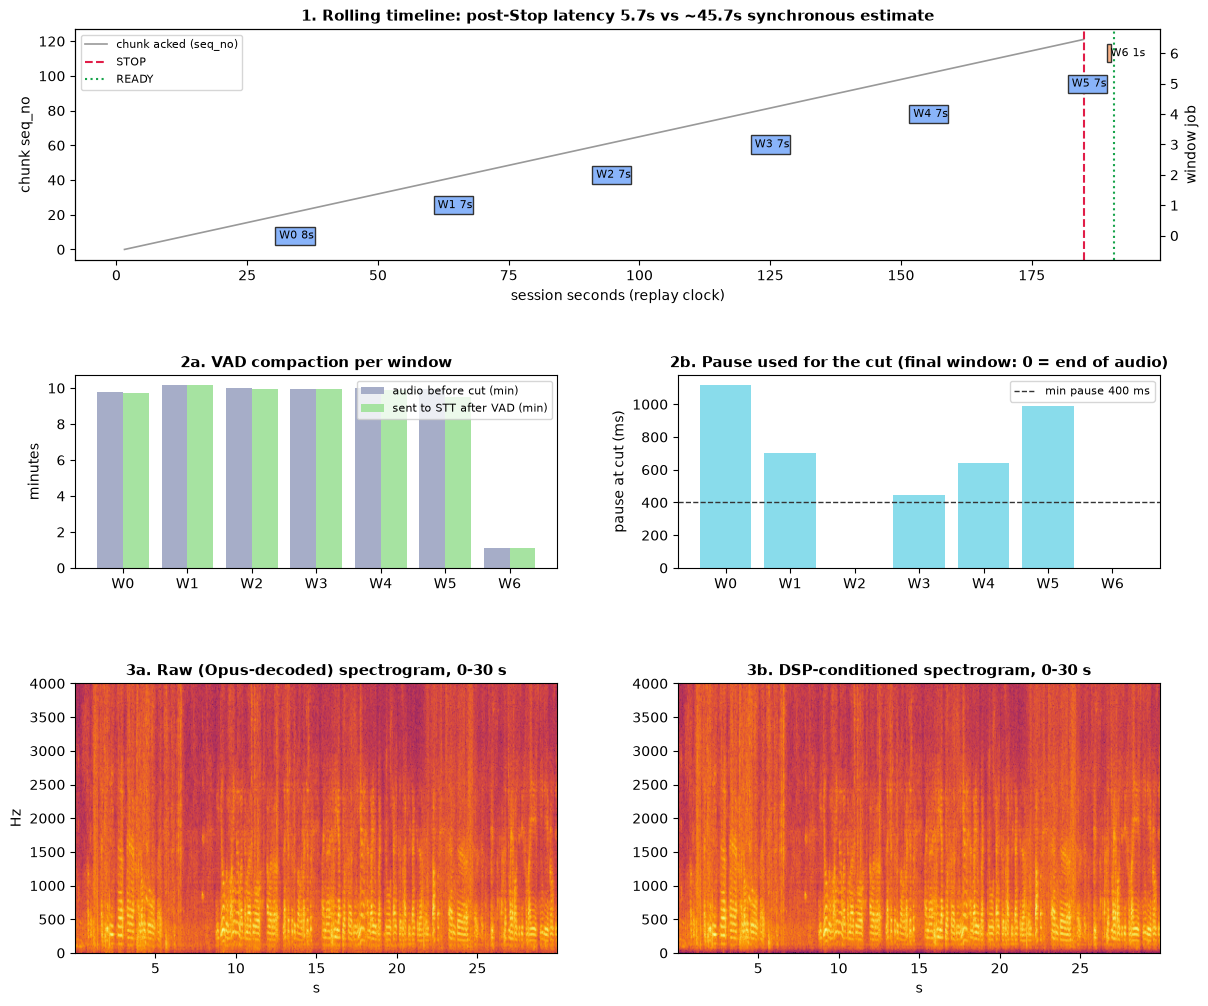

📊 saved /run/media/rtx/Files/Code/ProProjects/lazynote/backend/notebooks/result/pipeline_phase1/04_analysis/phase1_rolling_analysis.png
Metric (first 30 s, window 0)    |        Raw |        DSP |     Delta
RMS (dB)                         |     -33.17 |     -18.49 |    +14.68
Peak (dB)                        |     -12.11 |      -0.45 |    +11.66
Sub-85 Hz energy ratio (dB)      |     -31.52 |     -38.43 |     -6.91


In [23]:
fig = plt.figure(figsize=(14, 12))
gs = fig.add_gridspec(3, 2, height_ratios=[1.2, 1, 1.4], hspace=0.5, wspace=0.25)

# Panel 1: timeline
ax = fig.add_subplot(gs[0, :])
acks = [session.chunk_ack_t[s] for s in sorted(session.chunk_ack_t)]
ax.plot(acks, range(len(acks)), color="#999999", lw=1.2, label="chunk acked (seq_no)")
ax.set_ylabel("chunk seq_no")
ax2 = ax.twinx()
for r in reps:
    ax2.barh(r["window_index"], r["finished_at_s"] - r["started_at_s"], left=r["started_at_s"], height=0.6,
             color="#89b4fa" if not r["final"] else "#fab387", edgecolor="#333")
    ax2.text(r["started_at_s"], r["window_index"], f" W{r['window_index']} {r['t_total_s']:.0f}s", va="center", fontsize=8)
ax2.set_ylabel("window job")
ax2.set_ylim(-0.8, max(3, len(reps)) - 0.2)
ax.axvline(session.t_stop, color="#e11d48", ls="--", label="STOP")
ax.axvline(session.t_ready, color="#16a34a", ls=":", label="READY")
ax.set_xlabel("session seconds (replay clock)")
ax.set_title(f"1. Rolling timeline: post-Stop latency {post_stop_latency_s:.1f}s vs ~{sync_baseline_s:.1f}s synchronous estimate", fontweight="bold", fontsize=11)
ax.legend(loc="upper left", fontsize=8)

# Panel 2a/2b: per-window audio and pause
labels = [f"W{r['window_index']}" for r in reps]
x = np.arange(len(reps))
ax = fig.add_subplot(gs[1, 0])
ax.bar(x - 0.2, [(r["cut_local_ms"]) / 60000 for r in reps], 0.4, label="audio before cut (min)", color="#a6adc8")
ax.bar(x + 0.2, [r["compacted_ms"] / 60000 for r in reps], 0.4, label="sent to STT after VAD (min)", color="#a6e3a1")
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylabel("minutes"); ax.legend(fontsize=8)
ax.set_title("2a. VAD compaction per window", fontweight="bold", fontsize=11)
ax = fig.add_subplot(gs[1, 1])
ax.bar(x, [r["cut_pause_ms"] for r in reps], color=["#f38ba8" if r["cut_reason"] == "forced_low_energy_frame" else "#89dceb" for r in reps])
ax.axhline(MIN_BREATH_PAUSE_MS, color="#333", ls="--", lw=1, label=f"min pause {MIN_BREATH_PAUSE_MS} ms")
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylabel("pause at cut (ms)"); ax.legend(fontsize=8)
ax.set_title("2b. Pause used for the cut (final window: 0 = end of audio)", fontweight="bold", fontsize=11)

# Panel 3: raw vs DSP sample (first 30 s of window 0)
raw_sig, raw_rate = load_wav_pcm(SAMPLES_DIR / "window0_raw_30s.wav")
dsp_sig, dsp_rate = load_wav_pcm(SAMPLES_DIR / "window0_dsp_30s.wav")
ax = fig.add_subplot(gs[2, 0])
Pxx, freqs, bins, im = ax.specgram(raw_sig, NFFT=1024, Fs=raw_rate, noverlap=512, cmap="inferno")
ax.set_ylim(0, 4000); ax.set_title("3a. Raw (Opus-decoded) spectrogram, 0-30 s", fontweight="bold", fontsize=11)
ax.set_xlabel("s"); ax.set_ylabel("Hz")
ax = fig.add_subplot(gs[2, 1])
Pxx, freqs, bins, im = ax.specgram(dsp_sig, NFFT=1024, Fs=dsp_rate, noverlap=512, cmap="inferno")
ax.set_ylim(0, 4000); ax.set_title("3b. DSP-conditioned spectrogram, 0-30 s", fontweight="bold", fontsize=11)
ax.set_xlabel("s")

plot_path = ANALYSIS_DIR / "phase1_rolling_analysis.png"
plt.savefig(plot_path, dpi=140, bbox_inches="tight")
plt.show()
print(f"\U0001f4ca saved {plot_path}")


def calculate_metrics(sig, rate):
    rms_db = 20 * np.log10(np.sqrt(np.mean(sig ** 2)) + 1e-9)
    peak_db = 20 * np.log10(np.max(np.abs(sig)) + 1e-9)
    fft_vals = np.abs(np.fft.rfft(sig))
    freqs = np.fft.rfftfreq(len(sig), 1.0 / rate)
    sub85_db = 10 * np.log10(np.sum(fft_vals[freqs < 85.0] ** 2) / (np.sum(fft_vals ** 2) + 1e-9) + 1e-9)
    return {"rms_db": float(rms_db), "peak_db": float(peak_db), "sub85_ratio_db": float(sub85_db)}

raw_m, dsp_m = calculate_metrics(raw_sig, raw_rate), calculate_metrics(dsp_sig, dsp_rate)
print(f"{'Metric (first 30 s, window 0)':<32} | {'Raw':>10} | {'DSP':>10} | {'Delta':>9}")
for k, label in [("rms_db", "RMS (dB)"), ("peak_db", "Peak (dB)"), ("sub85_ratio_db", "Sub-85 Hz energy ratio (dB)")]:
    print(f"{label:<32} | {raw_m[k]:>10.2f} | {dsp_m[k]:>10.2f} | {dsp_m[k]-raw_m[k]:>+9.2f}")

## 13. Export: transcript, summary and the implementation contract

Written outputs:
- `03_transcripts/transcript_segments.jsonl` and `transcript.txt` (timestamp pills `[mm:ss]`). **With `SimulatedSTT` the text is placeholder**: the file only demonstrates the global-timeline layout.
- `05_state/phase1_summary.json` — configuration, per-window reports (without the offset-map detail), latency and storage numbers.
- `05_state/session_state.json` and `pipeline_log.jsonl` — PostgreSQL-equivalent state and the worker event log.

In [24]:
with open(TRANSCRIPT_DIR / "transcript_segments.jsonl", "w") as f:
    for s in session.transcript:
        f.write(json.dumps(s, ensure_ascii=False) + "\n")
(TRANSCRIPT_DIR / "transcript.txt").write_text("\n".join(f"{s['timestamp_pill']} {s['text']}" for s in session.transcript))

summary = {
    "config": {"source": SOURCE_AUDIO.name, "chunk_sec": CHUNK_SEC, "window_chunks": WINDOW_CHUNKS,
               "min_breath_pause_ms": MIN_BREATH_PAUSE_MS, "carryover_search_sec": CARRYOVER_SEARCH_SEC,
               "max_silence_ms": MAX_SILENCE_MS, "speech_pad_ms": SPEECH_PAD_MS, "vad_threshold": VAD_THRESHOLD,
               "dsp_chain": STT_FILTER_CHAIN, "stt_provider": stt_provider.name, "diarization": False,
               "replay_speedup": REPLAY_SPEEDUP, "flush_intermediates": FLUSH_INTERMEDIATES, "vad_source": VAD_SOURCE},
    "lecture": {"duration_s": SOURCE_DURATION_S, "used_s": EFFECTIVE_DURATION_S, "chunks": len(chunk_manifest)},
    "latency": {"recording_replay_s": recording_wall_s, "post_stop_latency_s": post_stop_latency_s,
                "sync_baseline_estimate_s": sync_baseline_s, "speedup_estimate": speedup,
                "windows_finished_before_stop": len(finished_before_stop), "backlog_at_stop": len(backlog)},
    "storage": {"peak_server_bytes": session.peak_server_bytes, "master": session.master_info},
    "windows": [{k: v for k, v in r.items() if k != "offset_map_islands"} for r in reps],
    "checks": [{"name": n, "passed": ok, "detail": d} for n, ok, d in checks],
}
(STATE_DIR / "phase1_summary.json").write_text(json.dumps(summary, indent=1, default=str))
session.save_state()

print("\U0001f4c1 Final result tree:")
for p in sorted(RESULT_DIR.rglob("*")):
    if p.is_file():
        print(f"   {str(p.relative_to(RESULT_DIR)):<58} {p.stat().st_size/1024:>10.1f} KB")

📁 Final result tree:
   00_source/source_probe.json                                       0.2 KB
   00_source/trap1_A_no_header.webm                                617.2 KB
   00_source/trap1_B_with_header.webm                              617.9 KB
   01_client/browser_stream.webm                                 14952.5 KB
   01_client/chunk_manifest.json                                    29.6 KB
   01_client/local_master_opfs.webm                              14950.1 KB
   01_client/upload_queue/chunk_0000.webm                          117.6 KB
   01_client/upload_queue/chunk_0001.webm                          123.3 KB
   01_client/upload_queue/chunk_0002.webm                          121.5 KB
   01_client/upload_queue/chunk_0003.webm                          121.7 KB
   01_client/upload_queue/chunk_0004.webm                          121.3 KB
   01_client/upload_queue/chunk_0005.webm                          124.0 KB
   01_client/upload_queue/chunk_0006.webm                          

## 14. Implementation contract for the real backend (read this before coding)

### 14.1 Endpoints and responsibilities
| Endpoint | Behaviour |
| --- | --- |
| `POST /api/v1/sessions/{id}/chunks` | Body = raw chunk bytes; headers `seq_no`, `sha256`. Verify checksum → parse first Cluster `Timecode` → store (R2) → upsert `AudioChunkLog(is_verified=true, start_ms)` → if `seq_no == 0` persist the header (`bytes[: first_cluster.start]`) → recompute `max_contiguous_seq` → enqueue rolling windows. **Idempotent per `(session, seq_no)`.** |
| `POST /api/v1/sessions/{id}/finalize` | Reject on sequence gaps. Enqueue the final window, wait/poll for the queue to drain, build + verify the master, flush transport chunks, return `status = ready`, `master_verified`. |
| `GET /api/v1/sessions/{id}` | Returns `status`, windows done/total, transcript so far (segments are committed progressively, so the UI can show live progress). |

### 14.2 Worker task `process_rolling_window(session_id, start_seq, end_seq, final)`
1. Acquire the **per-session sequential lock** (or chain after the previous window). Idempotency key `stt_win:{session_id}:{start_seq}_{end_seq}` (unique constraint).
2. Stitch `header + chunk[start..end]` (header omitted when `start_seq == 0`) → FFmpeg decode + linear DSP chain (§6.1) → 16 kHz mono PCM.
3. Prepend previous carryover (conditioned PCM; stored in R2 or local volume).
4. Silero VAD with `min_silence 400 ms`, `pad 0` → `choose_cut` (§6.2); `final` ⇒ cut at end.
5. Compact `[0..cut]` (bridge < 2.5 s, pad 250 ms) and build `TimestampOffsetMap` with **global** ms (§6.3).
6. STT with `diarization=False`; project each segment to global wall-clock ms; insert `TranscriptSegment(seq_index, start_ms, end_ms, text)` with a monotonically increasing `seq_index`.
7. Save `[cut..end]` as carryover; update `last_processed_chunk_seq`, `carryover_start_ms`, `carryover_ms` **in the same DB transaction as the segment inserts** (so a crash never double-inserts or loses a tail).
8. Flush intermediates (stitched webm, DSP wav, compacted wav, consumed carryover).

### 14.3 Flushing policy (Trap 4)
| Artifact | When flushed |
| --- | --- |
| `stitched.webm`, `dsp_conditioned.wav`, `vad_compacted.wav` | right after each window's STT is committed |
| previous `carryover_tail.wav` | once the next window committed |
| server transport chunks + header | **only after** `master_raw.webm` is built **and verified** |
| `master_raw.webm` | **never** (source of truth for re-transcription / revisions) |
| client upload queue (IndexedDB) | only after the server returns `master_verified = true` |
| client local master (OPFS) | never automatically (offline playback) |

### 14.4 Failure handling and open items
- **Crash/retry safety:** because transport chunks live until finalize, any window can be recomputed from `last_processed_chunk_seq`; the carryover tail is derivable from the previous window, so persist it (R2) rather than only in memory.
- **Out-of-order / lost uploads:** windows trigger on `max_contiguous_seq`, not on arrival count; a missing chunk stalls the rolling trigger (client retries) and finalize rejects gaps.
- **Forced cuts:** `cut_reason = forced_low_energy_frame` should be logged/metric'd; consider widening `CARRYOVER_SEARCH_SEC` before accepting a mid-speech cut.
- **Backlog:** alert when `now - enqueued_at` of a window grows (workers slower than real time); rolling gains vanish if processing time > recording time of the window.
- **Timecode scale / unknown-size clusters:** the walker assumes 1 ms ticks and known-size clusters (Chrome/FFmpeg). Add a fallback (parse `TimecodeScale`, resync on Cluster ID) if other browsers/encoders are supported (e.g. Safari emits MP4/AAC instead of WebM).
- **Not validated here:** real STT accuracy, STT latency, provider limits on file size/duration (Sarvam batch vs. REST limits), WER impact of the DSP chain, cut-boundary word-level quality with a real transcript. Re-run with `LAZYNOTE_STT_PROVIDER=deepgram` (or a Sarvam provider implementing the §7 contract) and inspect the words around each `cut_global_ms`.
- **Notes/LLM stage:** unchanged from the base notebook; runs once after the final window over the full `TranscriptSegment` list (timestamp pills `[mm:ss]` from `start_ms`).